## Import libraries

In [1]:
# Imports necessary to execute the code
from pathlib import Path
from careamics_portfolio import PortfolioManager
import matplotlib.pyplot as plt
import numpy as np
import tifffile
import random
import shutil

/opt/.pixi/envs/napari-careamics-default/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Import the dataset

The dataset can be directly downloaded using the `careamics-portfolio` package, which
uses `pooch` to download the data.

The CARE U2OS dataset is composed of thousands of examples organized in train and test:

- train
    - low: low SNR data
    - GT: high SNR data
- test
    - low: low SNR data
    - GT: high SNR data
 


In [2]:
# instantiate data portfolio manage
portfolio = PortfolioManager()

In [3]:
print(portfolio)

Portfolio:
Denoising datasets: ['N2N_SEM', 'N2V_BSD68', 'N2V_SEM', 'N2V_RGB', 'Flywing', 'Convallaria', 'CARE_U2OS', 'Tribolium']
DenoiSeg datasets: ['DSB2018_n0', 'DSB2018_n10', 'DSB2018_n20', 'Flywing_n0', 'Flywing_n10', 'Flywing_n20', 'MouseNuclei_n0', 'MouseNuclei_n10', 'MouseNuclei_n20']


In [4]:
portfolio.denoising.Flywing.description

'Image of a membrane-labeled fly wing (35x692x520 pixels).'

In [5]:
# # and download the data
data_dir = Path("../data_careamics")
# download = portfolio.denoising.CARE_U2OS.download(root_path)
# download = portfolio.denoising.Convallaria.download(root_path)
# download = portfolio.denoiseg.MouseNuclei_n20.download(root_path)

# path to the training data
root = data_dir / "denoising-CARE_U2OS.unzip" / "data" / "U2OS"
# train_path = root_path / "train" / "low"
# target_path = root_path / "train" / "GT"

## Make a reproducible 80/10/10 split

Set `N_IMAGES` to the number of low-high SNR image pairs to sample. It must be a positive multiple of 10 so the train, test, and validation sets remain exactly 80%, 10%, and 10%. `SPLIT_SEED` controls which pairs are selected and keeps the split reproducible. We use only images from the training dataset. Each image pair is copied as TIFF, and is goes to the high and low folder respectively. The original source files are unchanged.

In [6]:
N_IMAGES = 500
SPLIT_SEED = 42
prepared_dir = data_dir / f"U2OS_splits_n{N_IMAGES}_seed{SPLIT_SEED}"

existing_tiffs = (
    [path for path in prepared_dir.rglob("*.tif") if path.is_file()]
    if prepared_dir.is_dir()
    else []
)

if existing_tiffs:
    print(f"Split already exists at {prepared_dir}; skipping.")
else:
    low_dir = root / "train" / "low"
    gt_dir = root / "train" / "GT"

    if not low_dir.is_dir() or not gt_dir.is_dir():
        raise FileNotFoundError(f"Expected low/ and GT/ under {root / 'train'}")

    low_files = sorted(low_dir.glob("*.tif"))
    if not low_files:
        raise FileNotFoundError(f"No .tif images found in {low_dir}")

    source_pairs = []
    for low_path in low_files:
        gt_path = gt_dir / low_path.name
        if not gt_path.is_file():
            raise FileNotFoundError(f"No matching GT image for {low_path}")
        source_pairs.append((low_path, gt_path))

    if N_IMAGES <= 0 or N_IMAGES % 10 != 0:
        raise ValueError("N_IMAGES must be a positive multiple of 10 for an exact 80/10/10 split")
    if N_IMAGES > len(source_pairs):
        raise ValueError(
            f"Requested {N_IMAGES} pairs, but only {len(source_pairs)} are available"
        )

    selected_pairs = random.Random(SPLIT_SEED).sample(source_pairs, N_IMAGES)
    n_train = N_IMAGES * 8 // 10
    n_test = N_IMAGES // 10

    split_groups = {
        "train": selected_pairs[:n_train],
        "test": selected_pairs[n_train:n_train + n_test],
        "validation": selected_pairs[n_train + n_test:],
    }

    assert len(split_groups["train"]) == n_train
    assert len(split_groups["test"]) == N_IMAGES // 10
    assert len(split_groups["validation"]) == N_IMAGES // 10

    for split_name, pairs in split_groups.items():
        split_low_dir = prepared_dir / split_name / "low"
        split_gt_dir = prepared_dir / split_name / "high"
        split_low_dir.mkdir(parents=True, exist_ok=True)
        split_gt_dir.mkdir(parents=True, exist_ok=True)

        for low_path, gt_path in pairs:
            shutil.copy2(low_path, split_low_dir / low_path.name)
            shutil.copy2(gt_path, split_gt_dir / gt_path.name)

    print(
        f"Copied {len(split_groups['train'])} train, "
        f"{len(split_groups['test'])} test, and "
        f"{len(split_groups['validation'])} validation pairs to {prepared_dir}"
    )

Split already exists at ../data_careamics/U2OS_splits_n500_seed42; skipping.


## Visualize data

We pick the first image from our split dataset on the train folder and visualize the differences.

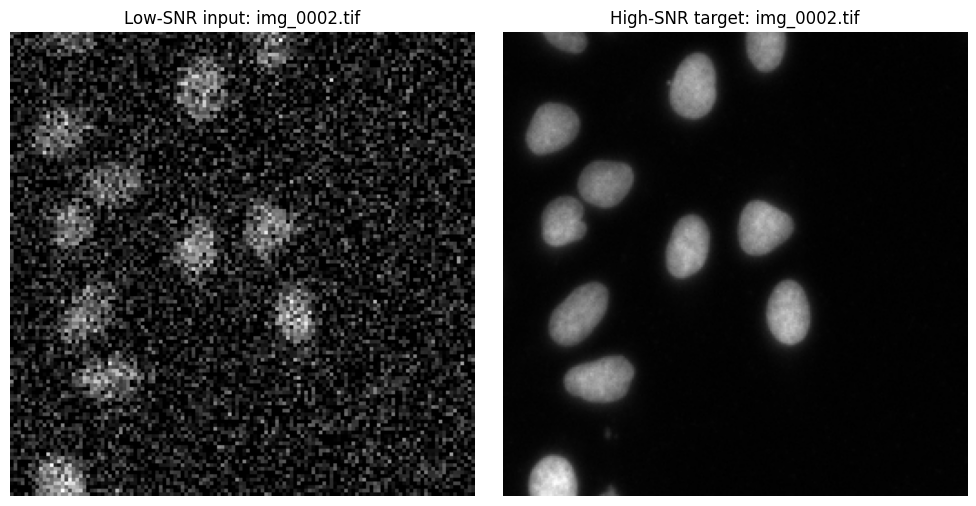

In [12]:
train_low_dir = prepared_dir / "train" / "low"
train_high_dir = prepared_dir / "train" / "high"

train_files = sorted(train_low_dir.glob("*.tif"))
if not train_files:
    raise FileNotFoundError(f"No training TIFF images found in {train_low_dir}")

train_pairs = []
for low_path in train_files:
    high_path = train_high_dir / low_path.name
    if not high_path.is_file():
        raise FileNotFoundError(f"No matching high-SNR image for {low_path}")
    train_pairs.append((low_path, high_path))

low_path, high_path = train_pairs[0]
low_image = tifffile.imread(low_path)
high_image = tifffile.imread(high_path)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(low_image, cmap="gray")
ax[0].set_title(f"Low-SNR input: {low_path.name}")
ax[1].imshow(high_image, cmap="gray")
ax[1].set_title(f"High-SNR target: {high_path.name}")

for axis in ax:
    axis.axis("off")

fig.tight_layout()
plt.show()